# Analyse exploratoire et modélisation – Boston Housing

**Légende** : 🔧 = cellule corrigée par rapport à votre version · ➕ = cellule ajoutée pour compléter l'analyse.

**Dictionnaire des variables**

| Variable | Signification |
|---|---|
| CRIM | Taux de criminalité par habitant |
| ZN | % de terrains résidentiels de grande taille (> 25 000 sq.ft) |
| INDUS | % de surfaces commerciales non-détail (industrie) |
| CHAS | 1 si le quartier borde la rivière Charles, 0 sinon |
| NOX | Concentration en oxydes d'azote (pollution) |
| RM | Nombre moyen de pièces par logement |
| AGE | % de logements construits **avant 1940** (ce n'est pas un âge en années) |
| DIS | Distance pondérée aux centres d'emploi |
| RAD | Indice d'accessibilité aux autoroutes |
| TAX | Taux de taxe foncière (pour 10 000 $) |
| PTRATIO | Ratio élèves / enseignants |
| B | Variable construite à partir de la proportion de population noire (⚠️ éthiquement problématique, exclue de la modélisation) |
| LSTAT | % de population à faible statut socio-économique |
| **MEDV** | **Valeur médiane des logements (en milliers de $) : variable cible** |

## 1. Imports et chargement des données

In [1]:
## 🔧 Bibliothèques 
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
## Importer la base de données (le fichier HousingData.csv doit être dans le même dossier que le notebook)
HousingData = pd.read_csv('HousingData.csv', sep=';')

## 2. Première exploration

In [3]:
## Dimension de la base de données
HousingData.shape

(506, 14)

In [ ]:
## Type de données
HousingData.dtypes

In [ ]:
## Aperçu des premières lignes
HousingData.head(8)

In [ ]:
## Noms des colonnes
HousingData.columns

In [4]:
## ➕ Informations générales (types + valeurs non nulles)
HousingData.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [5]:
## Statistiques descriptives
## À regarder : écart moyenne/médiane (asymétrie), min/max (extrêmes), count (valeurs manquantes)
HousingData.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,486.0,3.611874,8.720192,0.00632,0.081900,0.253715,3.560263,88.9762
ZN,486.0,11.211934,23.388876,0.00000,0.000000,0.000000,12.500000,100.0000
INDUS,486.0,11.083992,6.835896,0.46000,5.190000,9.690000,18.100000,27.7400
CHAS,486.0,0.069959,0.255340,0.00000,0.000000,0.000000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.538000,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.208500,6.623500,8.7800
AGE,486.0,68.518519,27.999513,2.90000,45.175000,76.800000,93.975000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.207450,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.000000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.000000,666.000000,711.0000


## 3. Qualité des données : valeurs manquantes et doublons

In [6]:
## 🔧 Valeurs nulles : nombre ET pourcentage par colonne
manquantes = pd.DataFrame({
    'nb_manquantes': HousingData.isnull().sum(),
    'pourcentage': (HousingData.isnull().mean() * 100).round(2)
})
manquantes[manquantes['nb_manquantes'] > 0]

,nb_manquantes,pourcentage
CRIM,20,3.95
ZN,20,3.95
INDUS,20,3.95
CHAS,20,3.95
AGE,20,3.95
LSTAT,20,3.95


**INTERPRETATION**

Tableau des valeurs manquantes

Six colonnes (CRIM, ZN, INDUS, CHAS, AGE, LSTAT) ont chacune 20 valeurs manquantes, soit 3,95 % (20 sur 506). Les autres colonnes sont complètes.

Le nombre est identique pour chaque colonne, ce qui indique un défaut de collecte plutôt qu'une absence liée à la valeur elle-même. Au total, cela fait 120 cellules vides. Si on supprimait les lignes incomplètes, on pourrait perdre jusqu'à environ 24 % des quartiers. C'est pourquoi l'imputation par la médiane est préférable à la suppression.

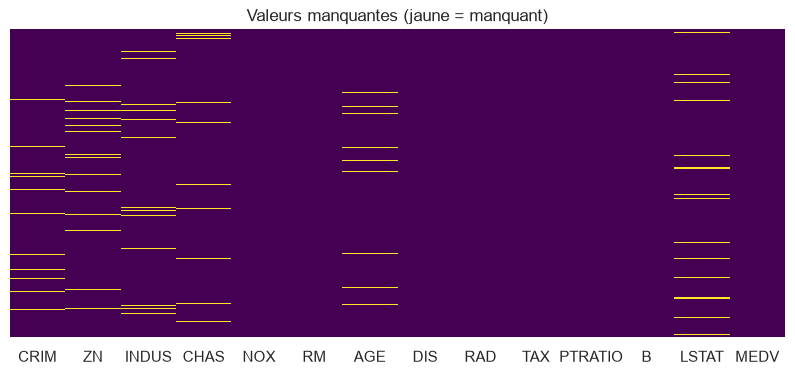

Lignes avec au moins une valeur manquante : 112


In [13]:
## ➕ Visualisation des valeurs manquantes
plt.figure(figsize=(10, 4))
sns.heatmap(HousingData.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Valeurs manquantes (jaune = manquant)')
plt.show()

print('Lignes avec au moins une valeur manquante :', HousingData.isnull().any(axis=1).sum())

**INTERPRETATION**

Heatmap des valeurs manquantes

Les traits jaunes sont dispersés au hasard : on ne voit ni bloc, ni zone entière vide, ni motif régulier. Les manques semblent donc répartis au hasard, sans lien visible avec une zone du fichier. Je ne peux pas le prouver avec ce seul graphique, mais cela rend l'imputation par la médiane raisonnable, car elle ne déforme pas la structure des données.

Les colonnes sans trait (NOX, RM, DIS, RAD, TAX, PTRATIO, B, MEDV) sont complètes, y compris la cible MEDV, ce qui est une bonne nouvelle pour la suite.

In [12]:
## Doublons : méthode duplicated()
HousingData.duplicated().sum()

np.int64(0)

## 4. Détection des valeurs aberrantes
On détecte **avant** de modifier les données. Deux méthodes : IQR (robuste, recommandée pour des variables asymétriques) et z-score (suppose une distribution proche de la normale).

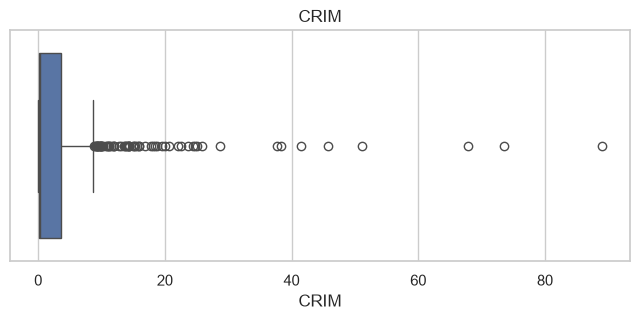

In [11]:
## Boxplot de CRIM
plt.figure(figsize=(8, 3))
sns.boxplot(x=HousingData['CRIM'])
plt.title('CRIM')
plt.show()

**INTERPRETATION**

Boxplot de CRIM
La boîte est écrasée contre 0 : la grande majorité des quartiers ont une criminalité très faible (la médiane est d'environ 0,25).
La moustache s'arrête vers 9, mais de très nombreux points s'étalent au-delà, jusqu'à 89. Trois quartiers sont particulièrement extrêmes (environ 68, 73 et 89).
La distribution est donc extrêmement asymétrique à droite.

Ces extrêmes sont des quartiers réellement dangereux, pas des erreurs de saisie. On les garde, mais on réduit leur poids avec log_CRIM, comme prévu.

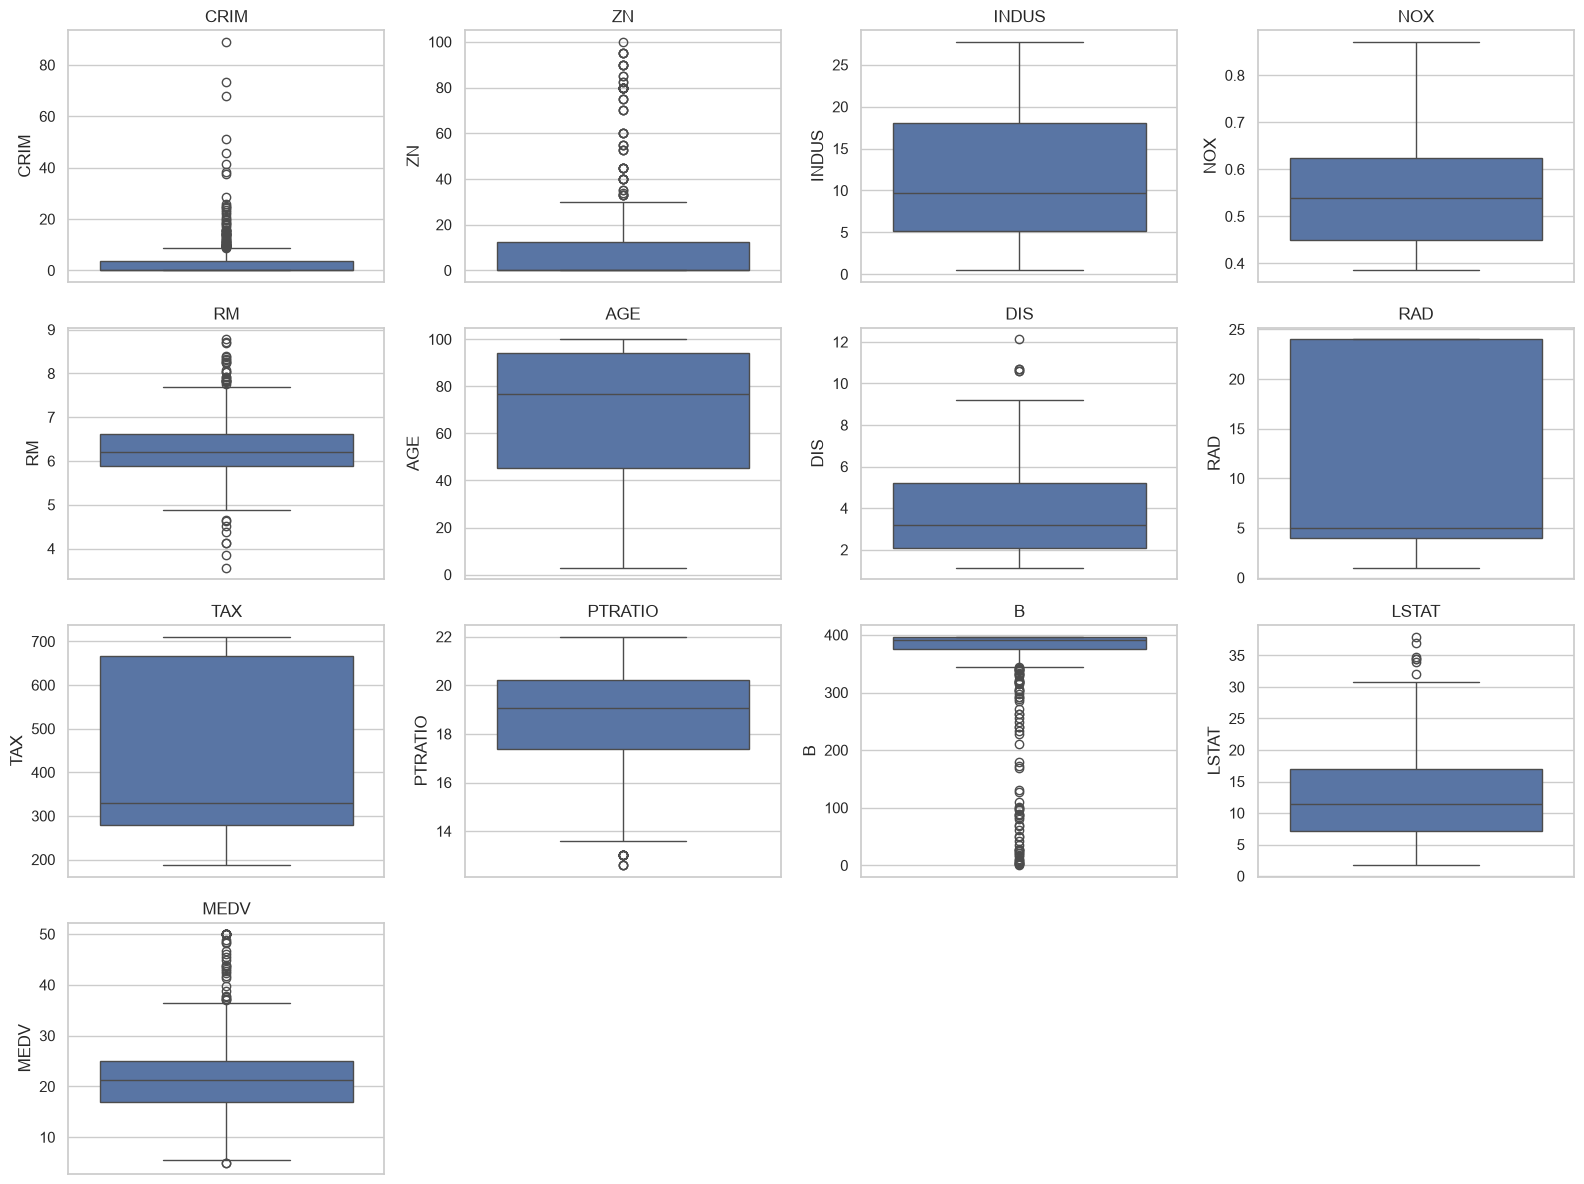

In [10]:
## ➕ Boxplots de toutes les variables numériques
cols_num = HousingData.select_dtypes(include='number').columns.drop('CHAS')
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cols_num):
    sns.boxplot(y=HousingData[col], ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(cols_num):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**INTERPRETATION**

Variable	        Lecture

CRIM	            Voir ci-dessus : énormément de valeurs extrêmes en haut.

ZN	                La boîte est quasi nulle (la plupart des quartiers    valent 0). Tout quartier avec plus de 30 environ est signalé « aberrant », alors que c'est simplement un quartier avec de grands terrains.

INDUS, NOX, TAX, AGE	    Aucun point aberrant.

RM:	                Points aberrants des deux côtés : quelques quartiers à moins de 5 pièces et d'autres à plus de 7,7. Ce sont des cas plausibles (quartiers modestes ou aisés).

AGE:	                Pas d'aberrantes, mais la boîte est large (environ 45 à 94) et la médiane est haute (environ 77) : majorité de logements anciens.

DIS:                Quelques points au-dessus de 9, des quartiers très éloignés des centres d'emploi.

RAD:                Boîte très étendue (de 4 à 24) : deux groupes de quartiers, confirmant ce qu'on avait vu dans l'histogramme.
PTRATIO	Quelques points bas, vers 13 : des quartiers très bien dotés en enseignants.

B:	                La boîte est écrasée tout en haut (vers 390), avec un long chapelet de points jusqu'à 0. La variable est fortement asymétrique vers la gauche.

LSTAT:	            Quelques points au-dessus de 31 environ : quartiers très défavorisés.

MEDV:	            Beaucoup de points au-dessus de 37 environ, jusqu'à 50 (valeur plafonnée), et un point très bas vers 5.

In [19]:
## 🔧 Fonctions de détection (réutilisables pour n'importe quelle colonne)
def bornes_iqr(serie, k=1.5):
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    # CORRECTION : la borne basse part de Q1 (et non de Q3 comme dans la version initiale)
    return q1 - k * iqr, q3 + k * iqr

def bornes_zscore(serie, seuil=3):
    s = serie.dropna()
    return s.mean() - seuil * s.std(), s.mean() + seuil * s.std()

def aberrantes(df, col, methode='iqr'):
    inf, sup = bornes_iqr(df[col]) if methode == 'iqr' else bornes_zscore(df[col])
    return df.loc[(df[col] < inf) | (df[col] > sup)]

In [6]:
## 🔧 Détection pour LSTAT (IQR) – borne basse corrigée
inf, sup = bornes_iqr(HousingData['LSTAT'])
print('Borne inférieure :', round(inf, 2))
print('Borne supérieure :', round(sup, 2))
display(aberrantes(HousingData, 'LSTAT', 'iqr'))

Borne inférieure : -7.62
Borne supérieure : 31.7


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
141,1.62864,0.0,21.89,0.0,0.624,5.019,100.0,1.4394,4,437,21.2,396.90,34.41,14.4
373,11.10810,0.0,18.10,0.0,0.668,4.906,100.0,1.1742,24,666,20.2,396.90,34.77,13.8
374,18.49820,0.0,18.10,0.0,0.668,4.138,100.0,1.1370,24,666,20.2,396.90,37.97,13.8
387,22.59710,0.0,18.10,0.0,0.700,5.000,89.5,1.5184,24,666,20.2,396.90,31.99,7.4
412,18.81100,0.0,18.10,0.0,0.597,4.628,100.0,1.5539,24,666,20.2,28.79,34.37,17.9
414,45.74610,0.0,18.10,0.0,0.693,4.519,100.0,1.6582,24,666,20.2,88.27,36.98,7.0
438,13.67810,0.0,18.10,0.0,0.740,5.935,87.9,1.8206,24,666,20.2,68.95,34.02,8.4


In [7]:
## 🔧 Détection par z-score pour AGE, CRIM et TAX (une seule cellule, plus de doublons)
for col in ['AGE', 'CRIM', 'TAX']:
    inf, sup = bornes_zscore(HousingData[col])
    ab = aberrantes(HousingData, col, 'zscore')
    print(f'{col} : bornes [{inf:.2f} ; {sup:.2f}] -> {len(ab)} valeurs aberrantes')

AGE : bornes [-15.48 ; 152.52] -> 0 valeurs aberrantes
CRIM : bornes [-22.55 ; 29.77] -> 8 valeurs aberrantes
TAX : bornes [-97.37 ; 913.85] -> 0 valeurs aberrantes


**INTERPRETATION**

Détection par z-score (AGE, CRIM, TAX)
AGE : 0 aberrante. Les bornes sont [−15,5 ; 152,5], or AGE est un pourcentage compris entre 0 et 100. Ces bornes ne sont donc pas réalistes : la méthode est inadaptée à une variable bornée.
CRIM : 8 aberrantes, avec des bornes de [−22,6 ; 29,8]. Ce sont les 8 points les plus éloignés du boxplot (environ 38, 38, 41, 46, 51, 68, 73, 89). Une criminalité négative n'existe pas, ce qui confirme que la borne basse n'a pas de sens ici.
TAX : 0 aberrante.

Le z-score a un défaut : les valeurs extrêmes gonflent elles-mêmes la moyenne et l'écart-type, donc les bornes s'élargissent et masquent une partie des aberrantes. C'est pourquoi l'IQR en détecte beaucoup plus.

In [14]:
## ➕ Tableau récapitulatif des valeurs aberrantes (IQR et z-score) pour toutes les variables
lignes = []
for col in cols_num:
    lignes.append({
        'variable': col,
        'aberrantes_IQR': len(aberrantes(HousingData, col, 'iqr')),
        'aberrantes_zscore': len(aberrantes(HousingData, col, 'zscore')),
        'asymetrie (skew)': round(HousingData[col].skew(), 2)
    })
resume_ab = pd.DataFrame(lignes).sort_values('aberrantes_IQR', ascending=False)
resume_ab

,variable,aberrantes_IQR,aberrantes_zscore,asymetrie (skew)
10,B,77,25,-2.89
0,CRIM,65,8,5.21
1,ZN,63,14,2.26
12,MEDV,40,0,1.11
4,RM,30,8,0.40
9,PTRATIO,15,0,-0.80
11,LSTAT,7,5,0.91
6,DIS,5,5,1.01
2,INDUS,0,0,0.30
3,NOX,0,0,0.73


**Décision sur les valeurs aberrantes** : on ne les supprime pas. Ce sont des quartiers réels (par ex. forte criminalité), donc de l'information utile. On réduit plutôt leur influence par une transformation logarithmique de `CRIM` (section 6) et par des modèles robustes (section 11).


Tableau récapitulatif IQR / z-score / asymétrie

Les variables les plus concernées :

Variable	IQR	    z-score	    Asymétrie
B	        77	     25	        −2,89
CRIM	    65	     8	         5,21
ZN	        63	     14	         2,26
MEDV	    40	     0	         1,11
RM	        30	     8	         0,40

Ce qu'il faut retenir :

L'IQR signale beaucoup plus de points que le z-score. C'est normal : l'IQR est plus strict et mieux adapté aux distributions asymétriques.
Une valeur « aberrante » n'est pas une erreur. B est asymétrique par construction, ZN vaut 0 pour la plupart des quartiers, et les 40 aberrantes de MEDV correspondent à des quartiers chers.
MEDV a 40 aberrantes par IQR mais 0 par z-score : la borne z-score est d'environ 50, donc rien ne dépasse, alors que le plafond à 50 est justement une contrainte du jeu de données.
Variables à asymétrie forte (supérieure à 1 en valeur absolue) : CRIM (5,21), B (−2,89), ZN (2,26), MEDV (1,11), et à la limite DIS (1,01) et RAD (1,00). Ce sont les candidates à une transformation (log, par exemple).
INDUS, NOX, TAX, AGE et RAD n'ont aucune valeur aberrante.

## 5. Traitement des valeurs manquantes
🔧 On impute par la **médiane** (robuste aux valeurs extrêmes) et pour **toutes** les colonnes concernées : `CRIM`, `ZN`, `INDUS`, `CHAS`, `AGE`, `LSTAT`. La version initiale ne traitait que `AGE`, `CRIM` et `TAX` (cette dernière n'avait pourtant aucune valeur manquante).

In [15]:
## Avant : on garde une trace des moyennes/médianes pour comparer
avant = HousingData[['CRIM', 'AGE', 'LSTAT']].describe().loc[['mean', '50%', 'std']]

colonnes_a_imputer = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'AGE', 'LSTAT']
for col in colonnes_a_imputer:
    HousingData[col] = HousingData[col].fillna(HousingData[col].median())

# CHAS est une variable binaire : on la remet en entier
HousingData['CHAS'] = HousingData['CHAS'].astype(int)

apres = HousingData[['CRIM', 'AGE', 'LSTAT']].describe().loc[['mean', '50%', 'std']]
print('AVANT imputation'); display(avant)
print('APRÈS imputation'); display(apres)

assert HousingData.isnull().sum().sum() == 0, 'Il reste des valeurs manquantes'
print('✔ Plus aucune valeur manquante')

AVANT imputation


,CRIM,AGE,LSTAT
mean,3.611874,68.518519,12.715432
50%,0.253715,76.800000,11.430000
std,8.720192,27.999513,7.155871


APRÈS imputation


,CRIM,AGE,LSTAT
mean,3.479140,68.845850,12.664625
50%,0.253715,76.800000,11.430000
std,8.570832,27.486962,7.017219


✔ Plus aucune valeur manquante


**INTERPRETATION**

La médiane ne change pas. C'est normal : on a rempli les cases vides avec la médiane elle-même.

La moyenne bouge légèrement, dans le sens de la médiane. Elle baisse pour CRIM et LSTAT (médiane inférieure à la moyenne) et monte pour AGE (médiane supérieure à la moyenne).

L'écart-type diminue d'environ 2 %. Les 20 valeurs ajoutées sont toutes « au centre », donc la dispersion est un peu sous-estimée. C'est le principal défaut de l'imputation par la médiane.

Verdict : les changements sont faibles, donc l'imputation n'a pas déformé les variables. Le message « ✓ Plus aucune valeur manquante » confirme que le contrôle est passé.

## 6. Création de nouvelles variables

In [16]:
## 🔧 classe_age avec pd.cut (plus rapide que la boucle, étiquettes corrigées)
## Rappel : AGE = % de logements construits avant 1940
HousingData['classe_age'] = pd.cut(
    HousingData['AGE'],
    bins=[0, 30, 50, 70, 90, 100],
    labels=['0-30 %', '30-50 %', '50-70 %', '70-90 %', '90-100 %'],
    include_lowest=True
)
HousingData['classe_age'].value_counts().sort_index()

classe_age
0-30 %       61
30-50 %      80
50-70 %      72
70-90 %     132
90-100 %    161
Name: count, dtype: int64

**INTERPRETATION**

Le total fait bien 506.

58 % des quartiers ont plus de 70 % de logements d'avant 1940 : le bâti est globalement ancien.

La classe 90-100 % est la plus fréquente, alors qu'elle est la plus étroite (10 points de large contre 20 ou 30 pour les autres). La concentration est donc encore plus forte que ne le montrent les effectifs.

Effet de l'imputation : les 20 valeurs manquantes de AGE ont reçu 76,8, qui tombe dans la classe 70-90 %. Cette classe contient donc environ 20 quartiers « artificiels ».

In [17]:
## ➕ log_CRIM : réduit l'asymétrie extrême de CRIM
HousingData['log_CRIM'] = np.log1p(HousingData['CRIM'])
print('Asymétrie CRIM     :', round(HousingData['CRIM'].skew(), 2))
print('Asymétrie log_CRIM :', round(HousingData['log_CRIM'].skew(), 2))

Asymétrie CRIM     : 5.32
Asymétrie log_CRIM : 1.36


In [18]:
## ➕ Indicateurs complémentaires issus de l'exploration
## - MEDV_plafonne : MEDV est plafonné à 50 (observations « censurées »)
## - groupe_RAD24 : groupe de quartiers très connectés aux autoroutes (RAD = 24, TAX élevé)
HousingData['MEDV_plafonne'] = (HousingData['MEDV'] >= 50).astype(int)
HousingData['groupe_RAD24'] = (HousingData['RAD'] == 24).astype(int)

print('Quartiers avec MEDV plafonné à 50 :', HousingData['MEDV_plafonne'].sum())
print('Quartiers du groupe RAD = 24      :', HousingData['groupe_RAD24'].sum())

Quartiers avec MEDV plafonné à 50 : 16
Quartiers du groupe RAD = 24      : 132


**INTERPRETATION**

16 quartiers ont un MEDV plafonné à 50, soit environ 3 % : ce sont des prix « au moins égaux à 50 », pas des prix exacts (données censurées). Une régression linéaire aura tendance à sous-estimer les prix de ces quartiers.

132 quartiers (26 %) forment le groupe RAD = 24. Il est assez grand pour être comparé aux autres de façon fiable, contrairement au groupe CHAS = 1, d'environ 35 quartiers.

## 7. Visualisation des distributions

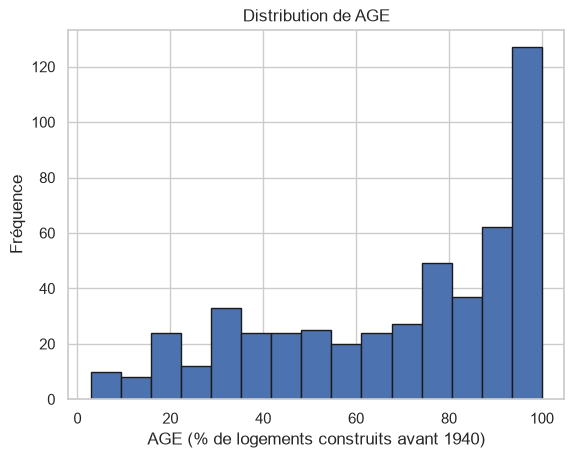

In [20]:
## Distribution de AGE
plt.hist(HousingData['AGE'], bins=15, edgecolor='k')
plt.xlabel('AGE (% de logements construits avant 1940)')
plt.ylabel('Fréquence')
plt.title('Distribution de AGE')
plt.show()

**INTERPRETATION**

La distribution est asymétrique vers la gauche (asymétrie négative, environ −0,58). Elle est assez plate entre 20 et 70 (20 à 33 quartiers par barre), puis monte nettement à partir de 70.

Le pic final (de 93 à 100 %) dépasse 120 quartiers, soit environ un quartier sur quatre.

Moyenne (68,8) inférieure à la médiane (76,8) : cohérent avec cette asymétrie.

Une barre isolée à environ 49 (vers 77-80 %) dépasse nettement ses voisines (27 et 37). C'est très probablement l'effet des 20 valeurs imputées à 76,8, pas une vraie particularité des données.

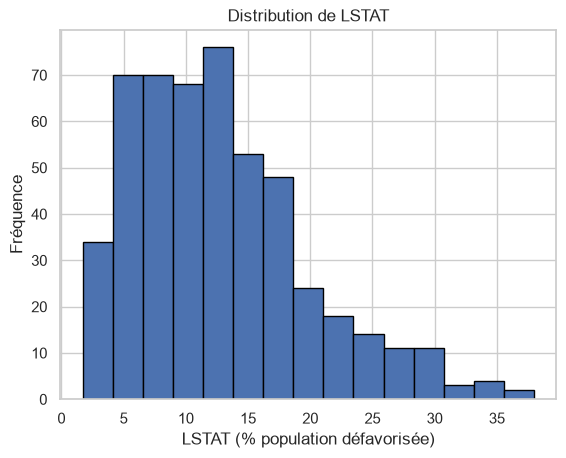

In [21]:
## Distribution de LSTAT
plt.hist(HousingData['LSTAT'], bins=15, edgecolor='black')
plt.xlabel('LSTAT (% population défavorisée)')
plt.ylabel('Fréquence')
plt.title('Distribution de LSTAT')
plt.show()

**INTERPRETATION**

La distribution est asymétrique vers la droite (asymétrie 0,91) : l'essentiel des quartiers a entre 4 et 19 % de population défavorisée, avec une queue qui va jusqu'à environ 38 %.

Le mode se situe autour de 11 à 14 %. Moins de 10 quartiers dépassent 31 %, ce sont les aberrantes détectées plus haut.

Moyenne (12,7) supérieure à la médiane (11,4) : cohérent avec la queue à droite.

Comme pour AGE, la barre la plus haute (environ 76) contient les valeurs imputées à 11,43. Une partie de ce pic est donc artificielle.

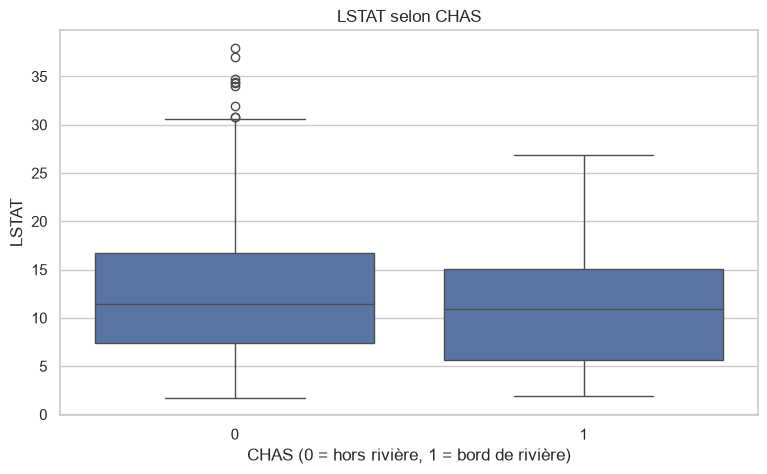

In [22]:
## LSTAT selon CHAS
plt.figure(figsize=(9, 5))
sns.boxplot(data=HousingData, x='CHAS', y='LSTAT')
plt.title('LSTAT selon CHAS')
plt.xlabel('CHAS (0 = hors rivière, 1 = bord de rivière)')
plt.ylabel('LSTAT')
plt.show()

**INTERPRETATION**

Les médianes sont proches : environ 11,4 hors rivière contre 10,9 au bord de la rivière.

La boîte de CHAS = 1 est un peu plus basse (environ 5,6 à 15,1 contre 7,4 à 16,7), et son maximum est plus faible (environ 27 contre 38).

Seul CHAS = 0 présente des points aberrants (au-dessus de 31), mais ce groupe est aussi plus de dix fois plus nombreux, donc plus susceptible d'en contenir.

Conclusion prudente : les quartiers au bord de la rivière sont très légèrement moins défavorisés, mais les deux groupes se chevauchent largement. Avec environ 35 quartiers, la différence reste peu fiable.

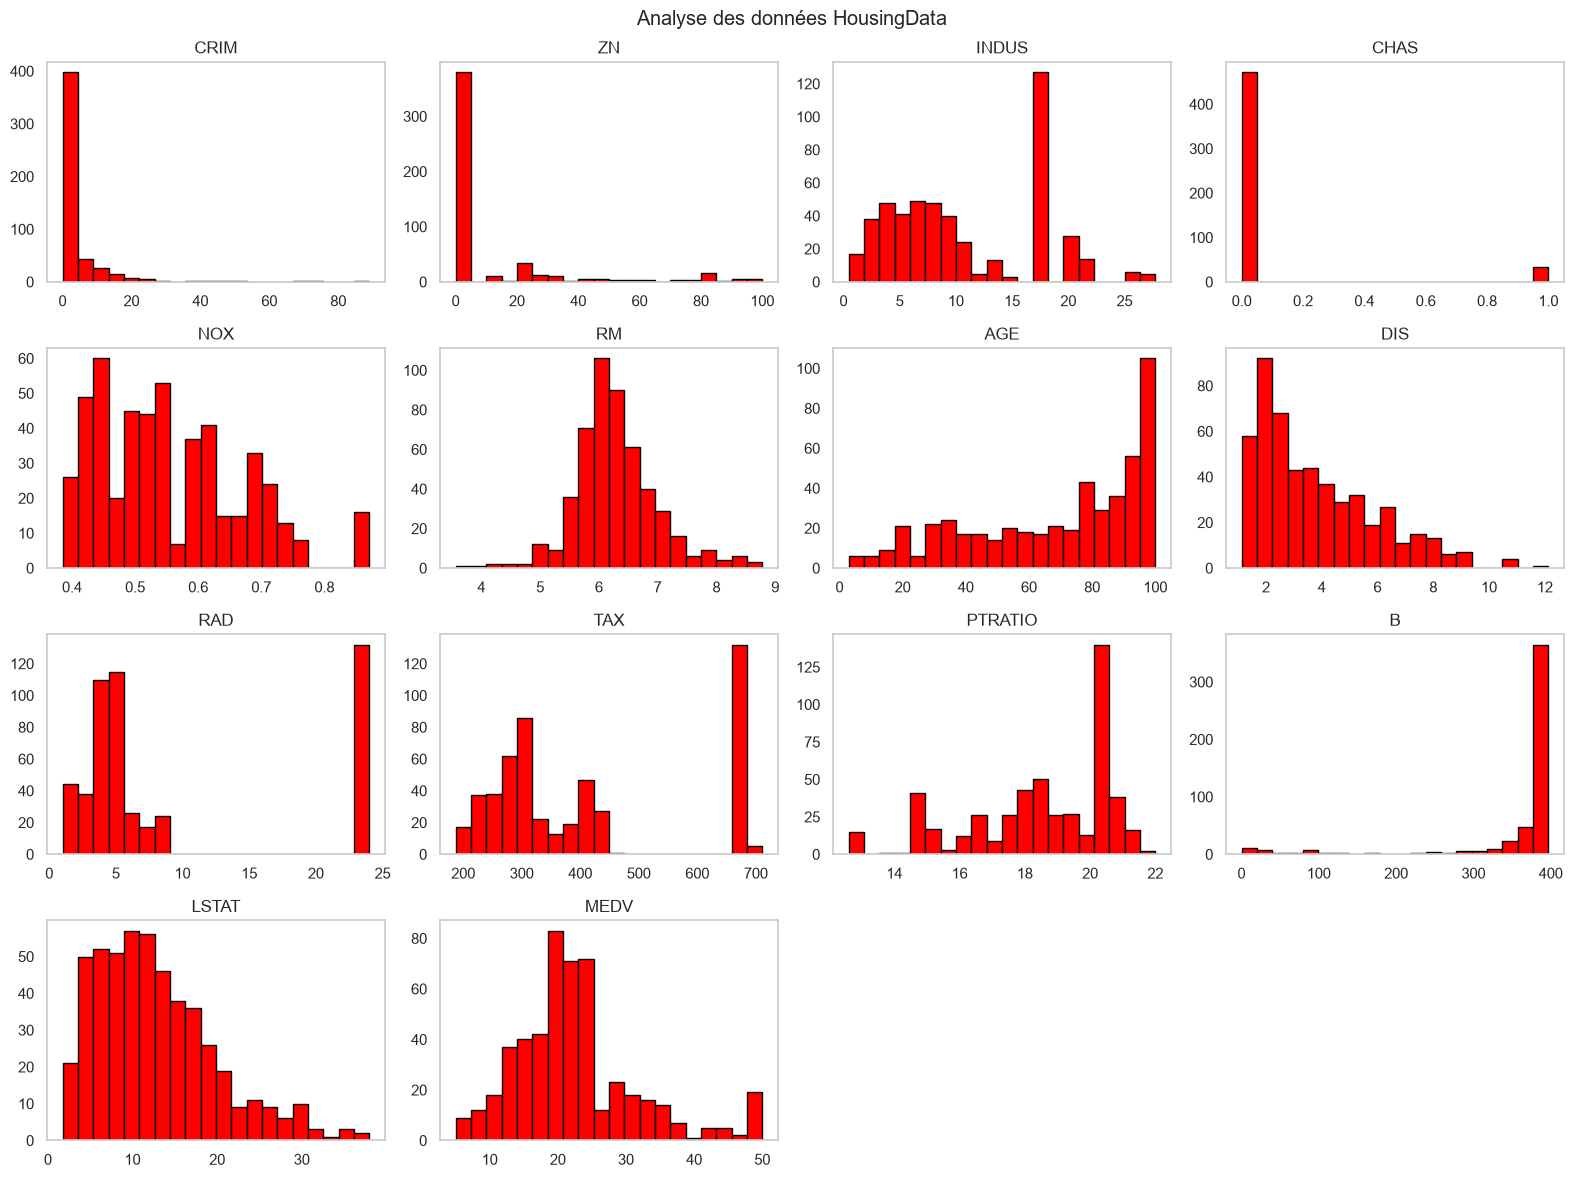

In [23]:
## Histogrammes de toutes les variables numériques d'origine
colonnes_numeriques = HousingData.select_dtypes(include='number').drop(
    columns=['log_CRIM', 'MEDV_plafonne', 'groupe_RAD24'])
colonnes_numeriques.hist(bins=20, figsize=(16, 12), color='red', edgecolor='black', grid=False)
plt.suptitle('Analyse des données HousingData')
plt.tight_layout()
plt.show()

**INTERPRETATION**


CRIM	Énorme pic près de 0, queue jusqu'à environ 89	Très asymétrique : candidate à log_CRIM

ZN	Environ 380 quartiers à 0	Majorité sans grands terrains. Le pic inclut les 20 valeurs imputées à 0

INDUS	Étalée de 0 à 12, pic isolé à environ 18 (≈ 125)	Un groupe de quartiers à fort taux d'industrie

CHAS	Quasi tout à 0, quelques 1	Très déséquilibrée
NOX	Plusieurs bosses, petit pic à environ 0,87	Distribution irrégulière, pas normale

RM	En cloche autour de 6,2	La plus proche d'une loi normale

AGE	Voir section 4	Pic à droite

DIS	Concentrée entre 1 et 4, queue à droite	Asymétrique à droite

RAD	Deux groupes : de 1 à 8, et 24 (≈ 130)	Variable en deux blocs

TAX	Deux groupes : 200 à 450, et environ 666 à 711 (≈ 130)	Même structure que RAD

PTRATIO	Pic à environ 20-20,5 (≈ 135)	Même groupe de quartiers

B	Presque tout vers 390-397, longue queue vers 0	Très asymétrique à gauche

LSTAT	Voir section 5	Asymétrique à droite

MEDV	Pic à 18-24, queue à droite, bosse finale à 50	Plafonnement du prix

Constat clé : les pics de INDUS (≈ 18), RAD (24), TAX (≈ 666) et PTRATIO (≈ 20,2) comptent tous environ 130 quartiers, ce qui correspond aux 132 quartiers du groupe RAD = 24. Ces quatre variables décrivent probablement le même ensemble de quartiers, ce qui explique leur forte corrélation (RAD et TAX à 0,91).


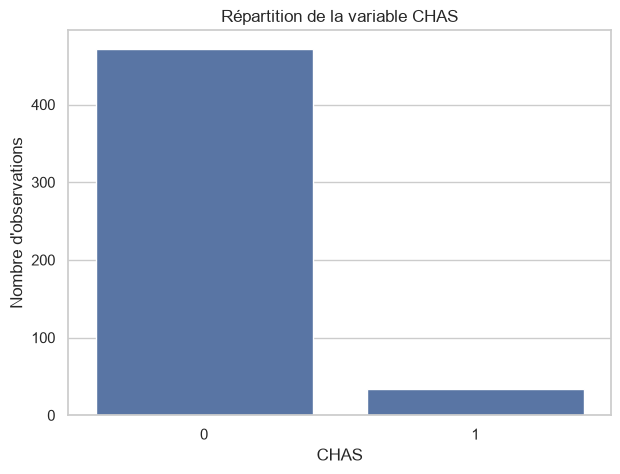

In [24]:
## 🔧 Répartition de CHAS (variable binaire) – le code traçait CRIM par erreur
plt.figure(figsize=(7, 5))
sns.countplot(data=HousingData, x='CHAS')
plt.title('Répartition de la variable CHAS')
plt.xlabel('CHAS')
plt.ylabel("Nombre d'observations")
plt.show()

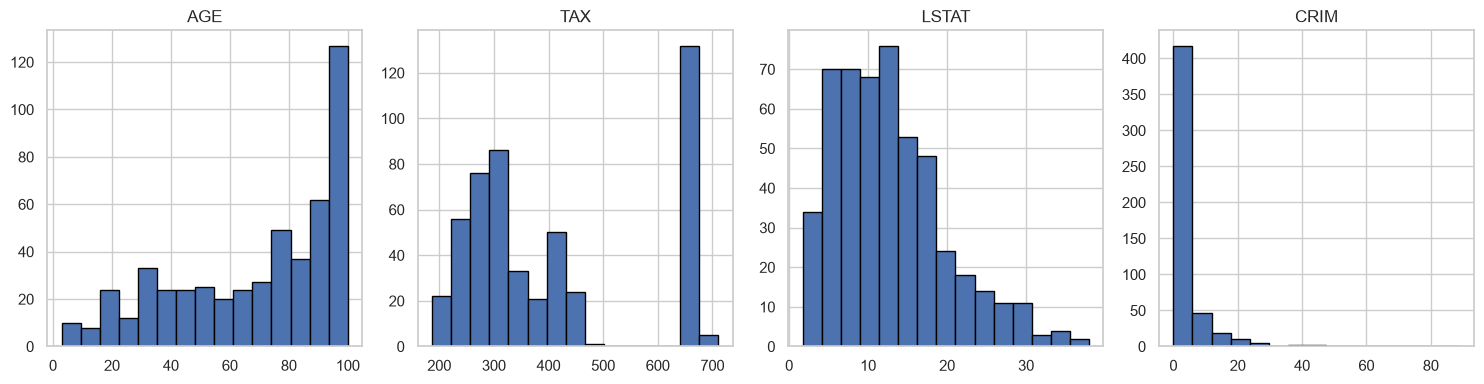

In [25]:
## Comparaison des 4 variables AGE, TAX, LSTAT, CRIM
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ['AGE', 'TAX', 'LSTAT', 'CRIM']):
    ax.hist(HousingData[col], bins=15, edgecolor='black')
    ax.set_title(col)
plt.tight_layout()
plt.show()

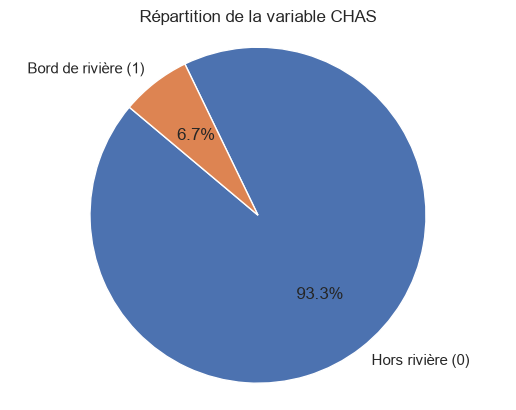

In [26]:
## Proportion de la variable CHAS
chas_counts = HousingData['CHAS'].value_counts().sort_index()
plt.pie(chas_counts.values, labels=['Hors rivière (0)', 'Bord de rivière (1)'],
        autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.title('Répartition de la variable CHAS')
plt.show()

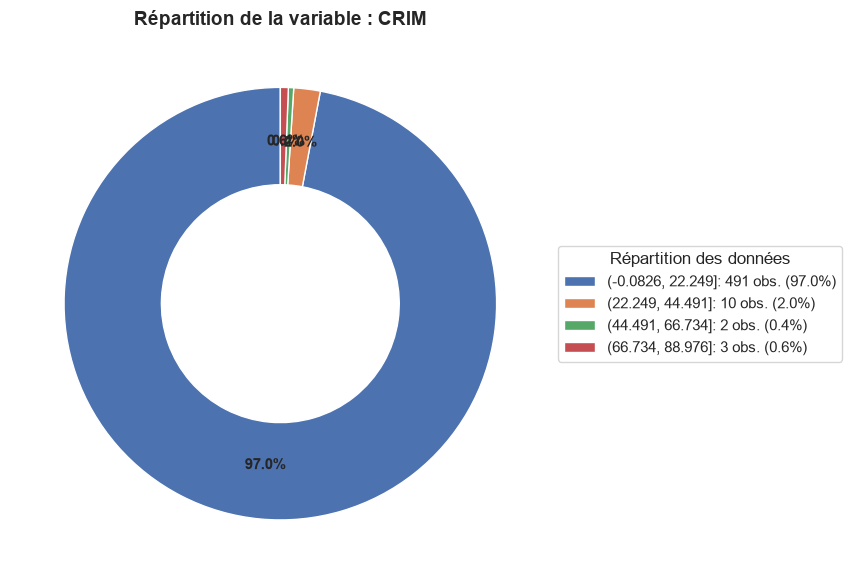

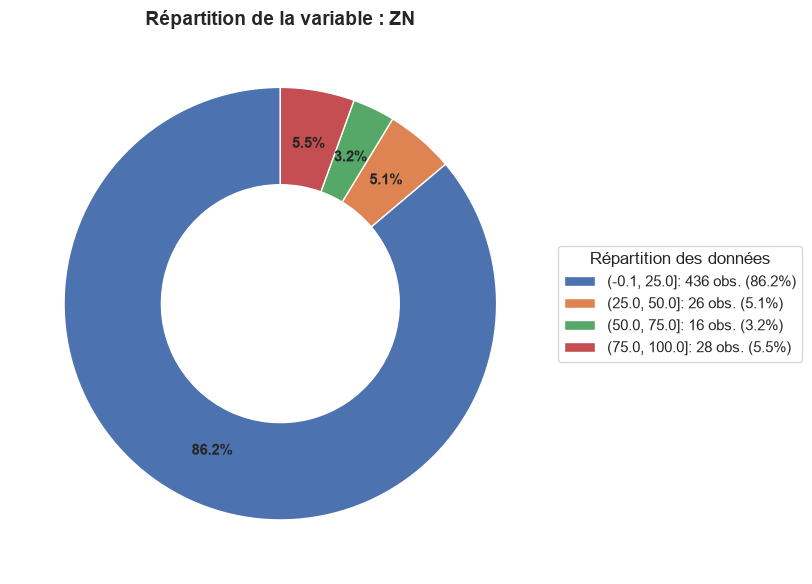

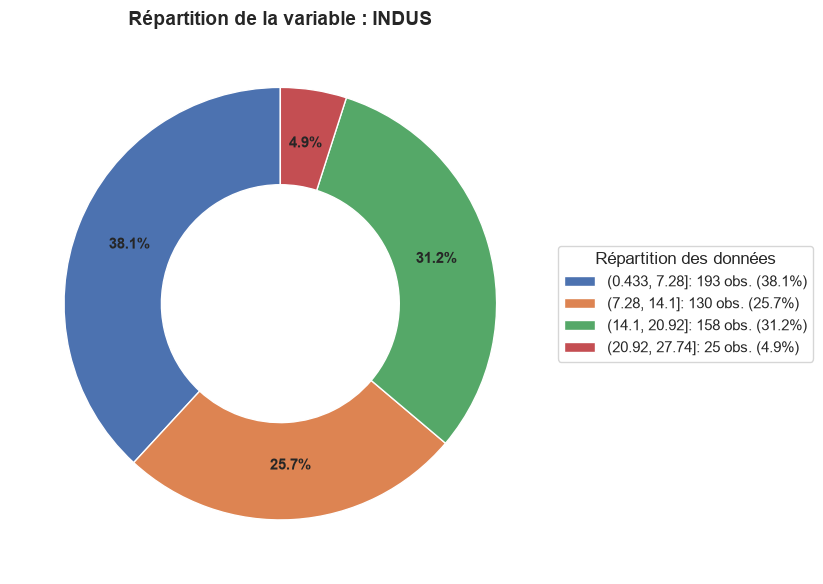

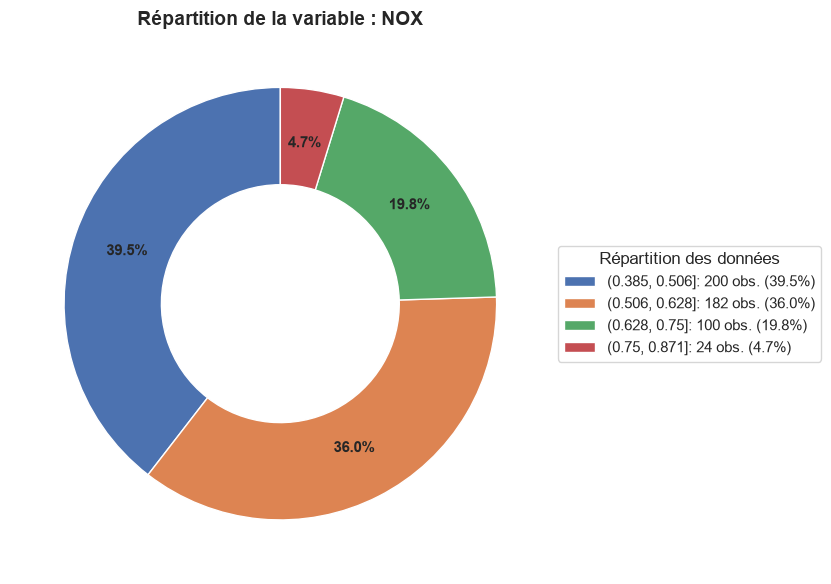

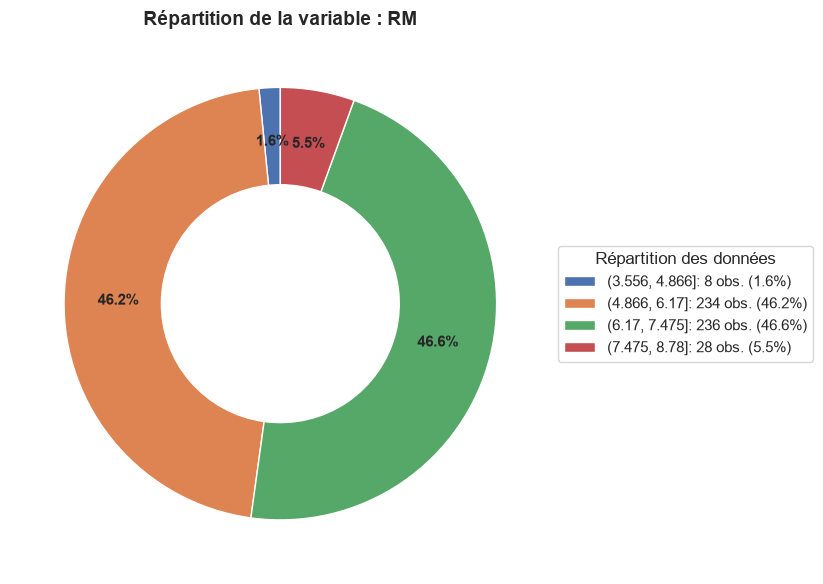

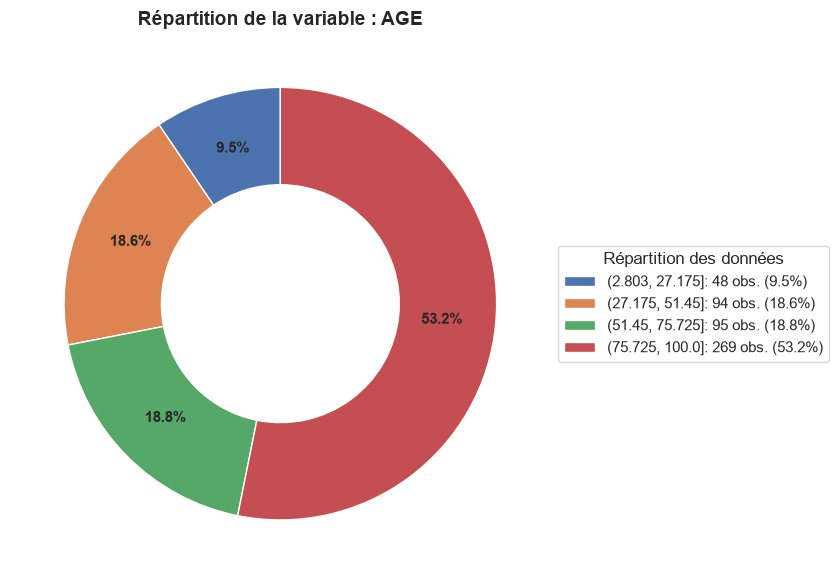

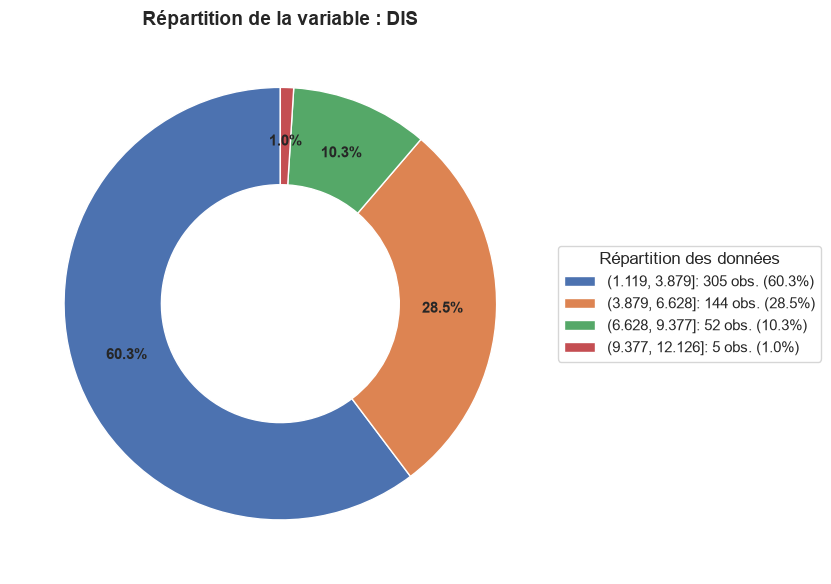

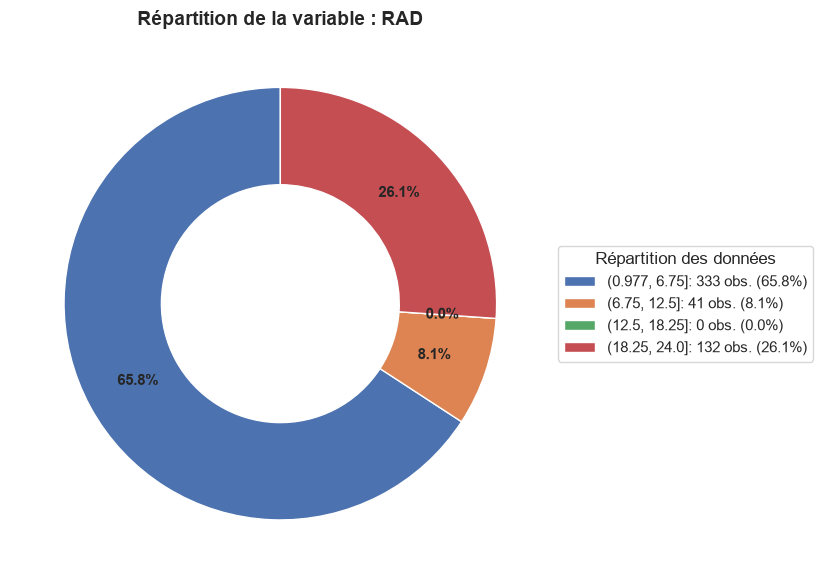

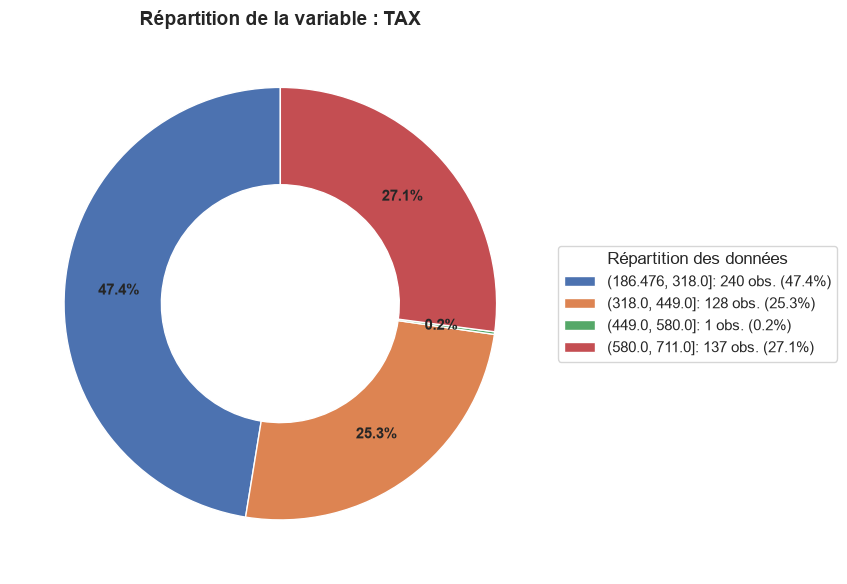

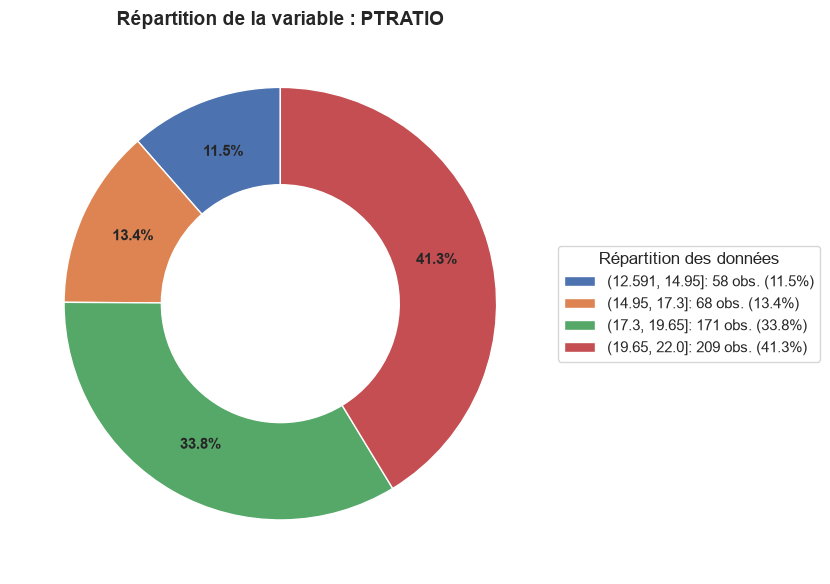

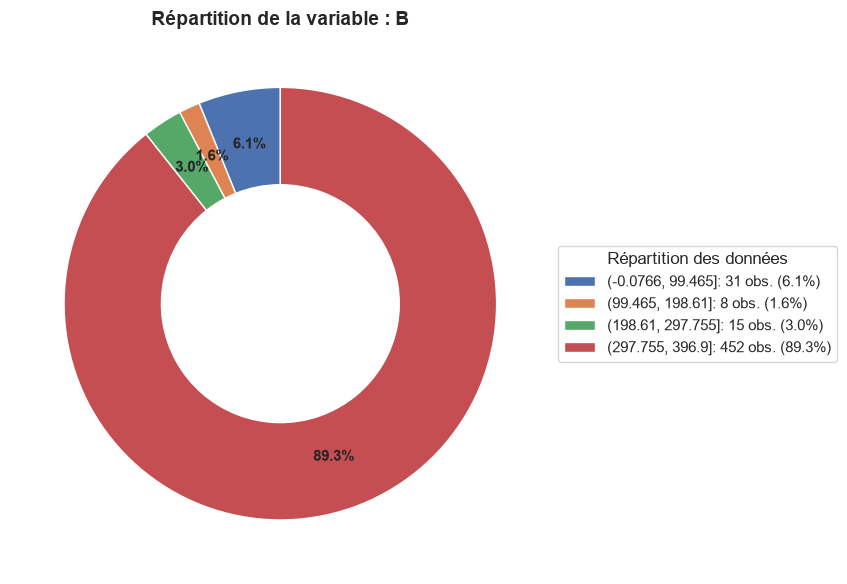

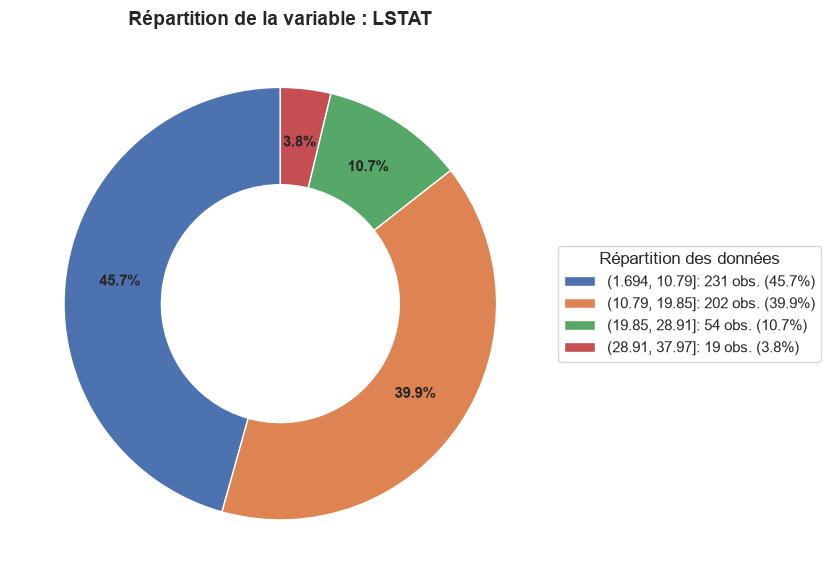

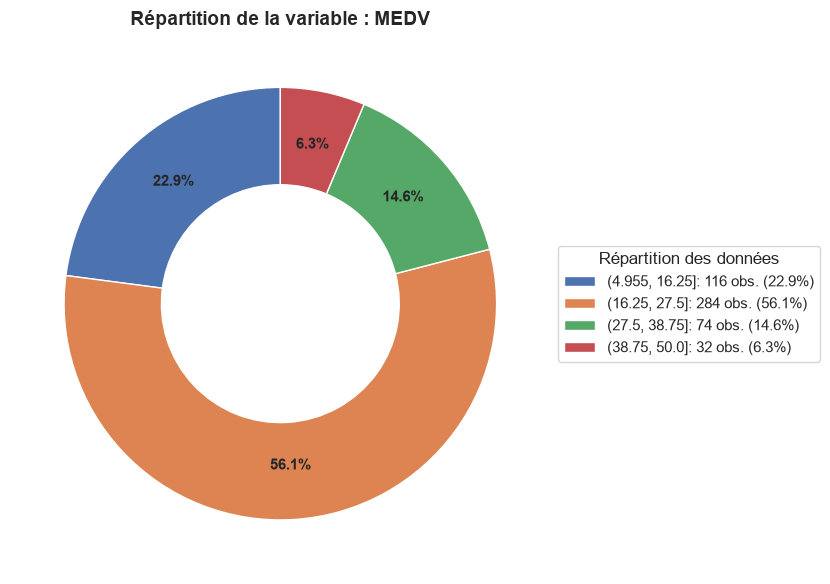

In [27]:
## 🔧 Répartition en 4 intervalles de chaque variable (version anneau)
## Correction : CHAS exclue (binaire), figures fermées après affichage.
## Remarque : pour des variables continues, les histogrammes ci-dessus restent plus lisibles.
for colonne in colonnes_numeriques.columns.drop('CHAS'):
    intervalles = pd.cut(HousingData[colonne], bins=4)
    repartition = intervalles.value_counts().sort_index()
    pourcentages = repartition / repartition.sum() * 100
    legendes = [f'{i}: {e} obs. ({p:.1f}%)' for i, e, p in zip(repartition.index, repartition.values, pourcentages.values)]

    fig, ax = plt.subplots(figsize=(12, 6))
    wedges, texts, autotexts = ax.pie(repartition.values, autopct='%1.1f%%', startangle=90,
                                      pctdistance=0.75, textprops={'fontsize': 11},
                                      wedgeprops={'width': 0.45, 'edgecolor': 'white'})
    for t in autotexts:
        t.set_fontweight('bold')
    ax.legend(wedges, legendes, title='Répartition des données', loc='center left', bbox_to_anchor=(1, 0.5))
    ax.set_title(f'Répartition de la variable : {colonne}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

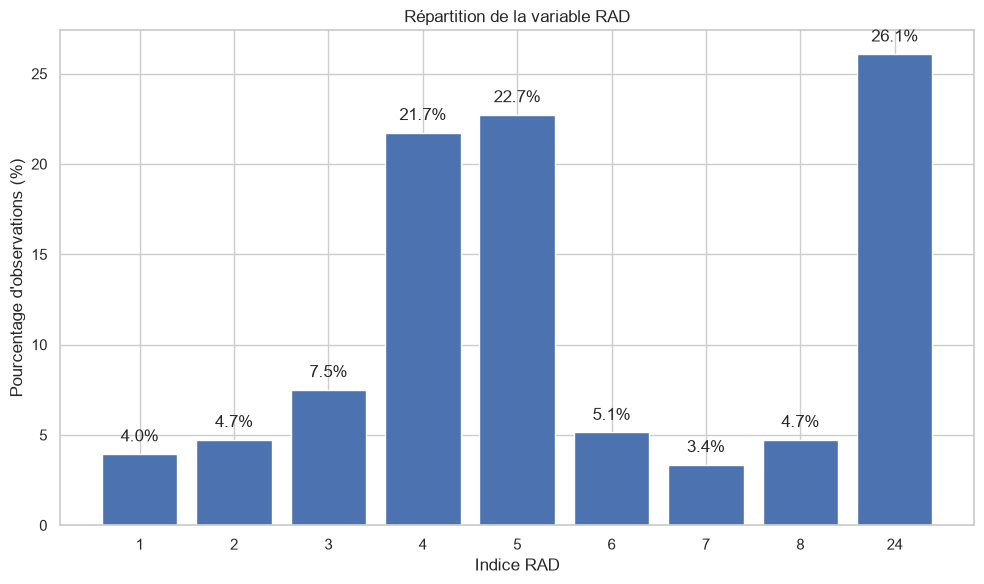

In [28]:
## Répartition de RAD (accessibilité aux autoroutes) en pourcentage
rad_pct = HousingData['RAD'].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(10, 6))
bars = plt.bar(rad_pct.index.astype(str), rad_pct.values)
plt.xlabel('Indice RAD')
plt.ylabel("Pourcentage d'observations (%)")
plt.title('Répartition de la variable RAD')
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 8. Corrélations

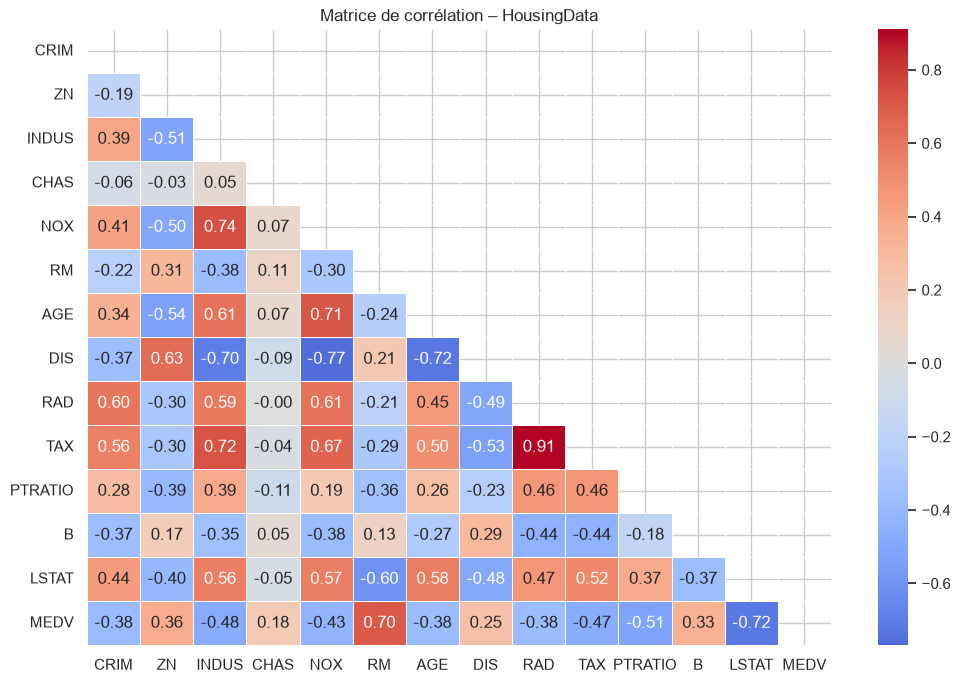

In [29]:
## 🔧 Matrice de corrélation (une seule version, triangle inférieur pour la lisibilité)
variables_corr = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
                  'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
correlation = HousingData[variables_corr].corr()

masque = np.triu(np.ones_like(correlation, dtype=bool))
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, mask=masque, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Matrice de corrélation – HousingData')
plt.show()

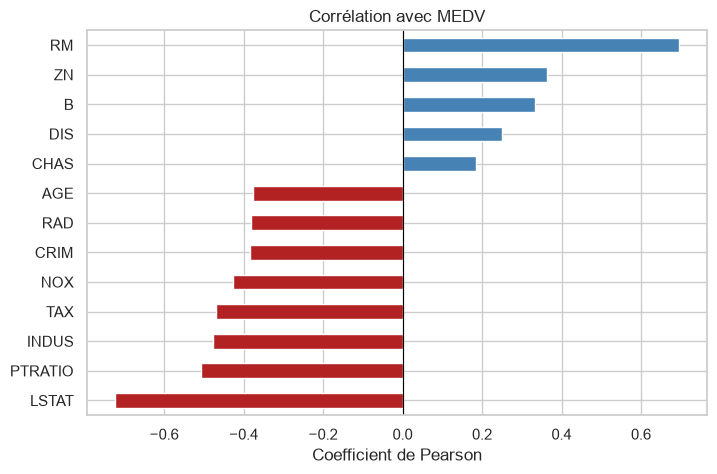

LSTAT     -0.72
RM         0.70
PTRATIO   -0.51
INDUS     -0.48
TAX       -0.47
NOX       -0.43
CRIM      -0.38
RAD       -0.38
AGE       -0.38
ZN         0.36
B          0.33
DIS        0.25
CHAS       0.18
Name: MEDV, dtype: float64

In [37]:
## ➕ Corrélation de chaque variable avec la cible MEDV
corr_medv = correlation['MEDV'].drop('MEDV').sort_values()
plt.figure(figsize=(8, 5))
corr_medv.plot.barh(color=['firebrick' if v < 0 else 'steelblue' for v in corr_medv])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Corrélation avec MEDV')
plt.xlabel('Coefficient de Pearson')
plt.show()
corr_medv.sort_values(key=abs, ascending=False).round(2)

In [38]:
## ➕ Paires de variables explicatives fortement corrélées (|r| > 0,7) -> risque de multicolinéarité
paires = (correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
          .stack().rename('r').reset_index())
paires.columns = ['var1', 'var2', 'r']
paires = paires[(paires['var1'] != 'MEDV') & (paires['var2'] != 'MEDV') & (paires['r'].abs() > 0.7)]
paires.sort_values('r', key=abs, ascending=False).round(2)

,var1,var2,r
121,RAD,TAX,0.91
63,NOX,DIS,-0.77
32,INDUS,NOX,0.74
91,AGE,DIS,-0.72
37,INDUS,TAX,0.72
62,NOX,AGE,0.71


In [39]:
## ➕ Corrélation de Spearman (robuste aux valeurs extrêmes et aux relations non linéaires)
spearman_medv = HousingData[variables_corr].corr(method='spearman')['MEDV'].drop('MEDV')
comparaison = pd.DataFrame({'Pearson': corr_medv, 'Spearman': spearman_medv}).round(2)
comparaison.sort_values('Spearman', key=abs, ascending=False)

,Pearson,Spearman
LSTAT,-0.72,-0.84
RM,0.70,0.63
INDUS,-0.48,-0.57
NOX,-0.43,-0.56
PTRATIO,-0.51,-0.56
TAX,-0.47,-0.56
AGE,-0.38,-0.54
CRIM,-0.38,-0.54
DIS,0.25,0.45
ZN,0.36,0.43


## 9. Relations avec la variable cible MEDV

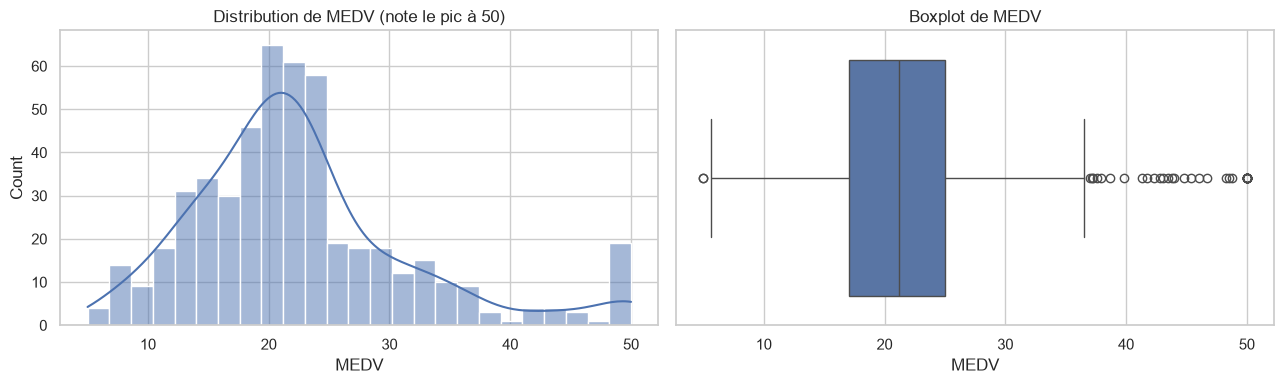

In [35]:
## ➕ Distribution de la cible MEDV
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(HousingData['MEDV'], bins=25, kde=True, ax=axes[0])
axes[0].set_title('Distribution de MEDV (note le pic à 50)')
sns.boxplot(x=HousingData['MEDV'], ax=axes[1])
axes[1].set_title('Boxplot de MEDV')
plt.tight_layout()
plt.show()

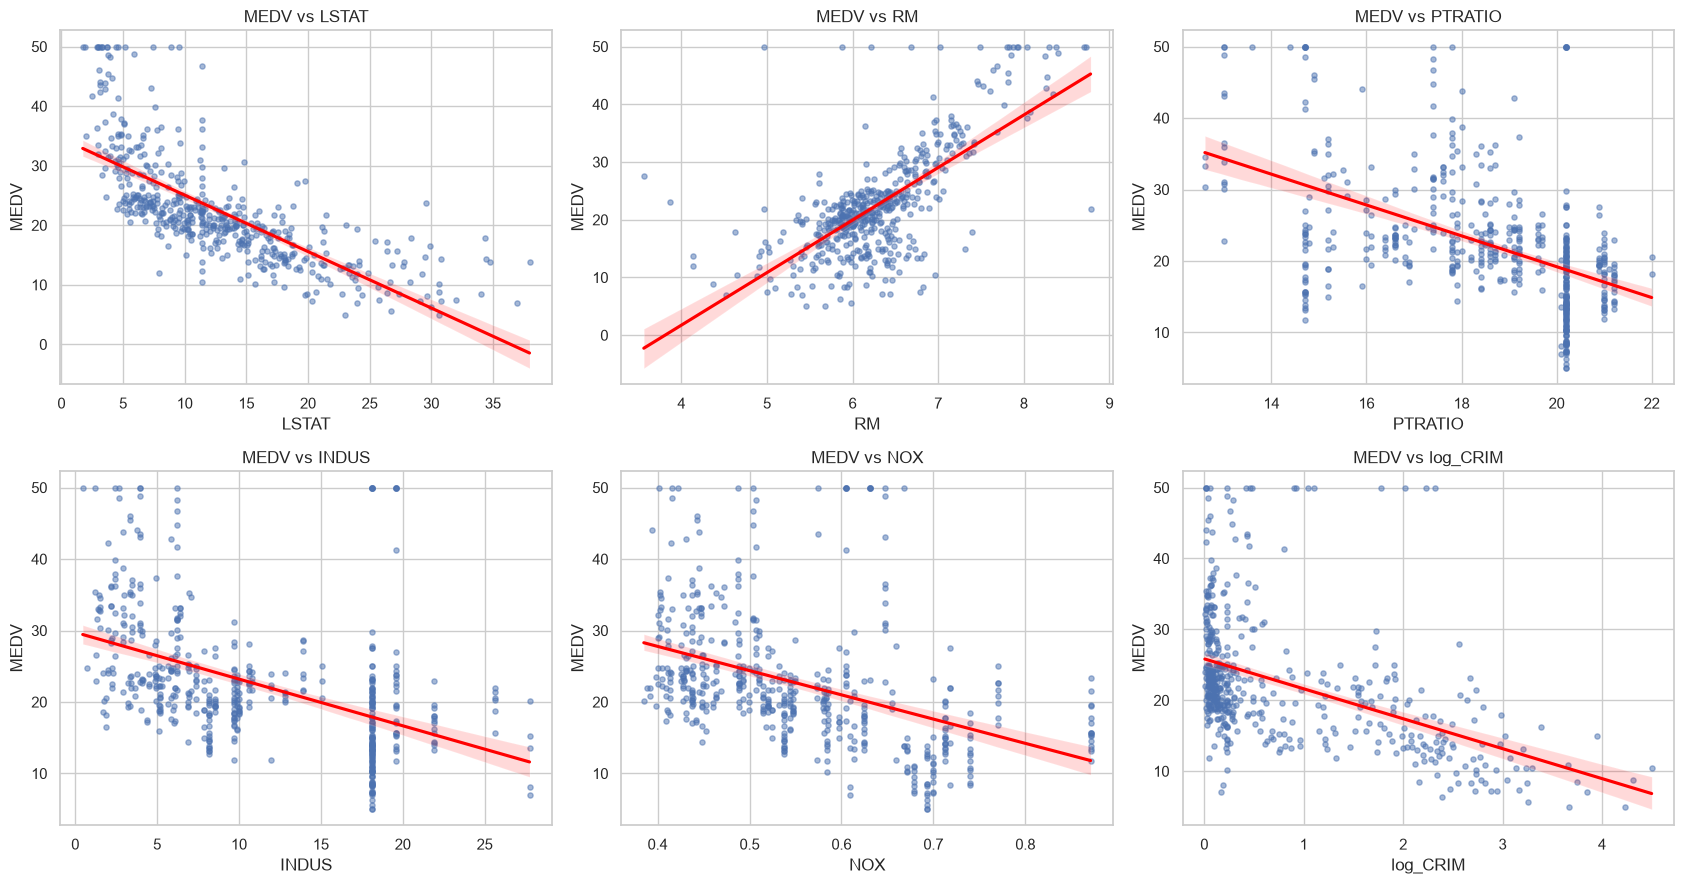

In [34]:
## ➕ Relation de MEDV avec les variables les plus corrélées
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, v in zip(axes.ravel(), ['LSTAT', 'RM', 'PTRATIO', 'INDUS', 'NOX', 'log_CRIM']):
    sns.regplot(data=HousingData, x=v, y='MEDV', ax=ax,
                scatter_kws={'s': 14, 'alpha': 0.5}, line_kws={'color': 'red'})
    ax.set_title(f'MEDV vs {v}')
plt.tight_layout()
plt.show()

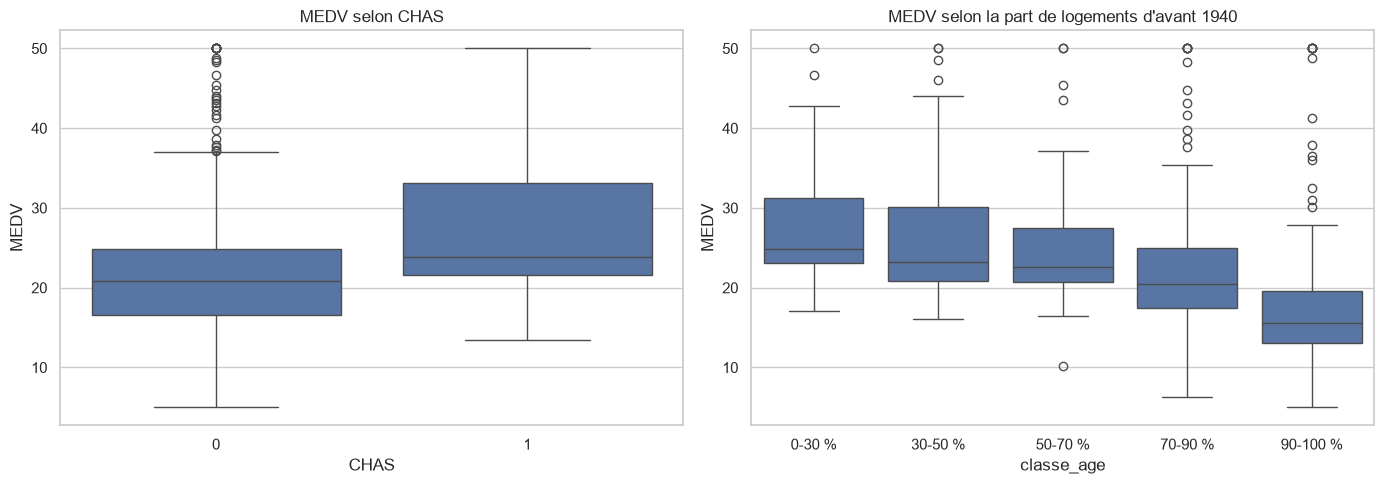

,count,mean,median
classe_age,,,
0-30 %,61,27.49,24.80
30-50 %,80,26.14,23.25
50-70 %,72,24.96,22.60
70-90 %,132,22.45,20.40
90-100 %,161,17.85,15.60


In [33]:
## ➕ MEDV selon CHAS et selon classe_age
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=HousingData, x='CHAS', y='MEDV', ax=axes[0])
axes[0].set_title('MEDV selon CHAS')
sns.boxplot(data=HousingData, x='classe_age', y='MEDV', ax=axes[1])
axes[1].set_title("MEDV selon la part de logements d'avant 1940")
plt.tight_layout()
plt.show()

HousingData.groupby('classe_age', observed=True)['MEDV'].agg(['count', 'mean', 'median']).round(2)

In [32]:
## ➕ Le groupe RAD = 24 est-il différent des autres quartiers ?
profil = HousingData.groupby('groupe_RAD24')[['MEDV', 'CRIM', 'TAX', 'PTRATIO', 'INDUS', 'NOX', 'LSTAT', 'RM']].median().round(2)
profil.index = ['Autres quartiers', 'Groupe RAD = 24']
profil

,MEDV,CRIM,TAX,PTRATIO,INDUS,NOX,LSTAT,RM
Autres quartiers,22.65,0.14,305.0,18.0,6.96,0.49,9.63,6.23
Groupe RAD = 24,14.40,8.49,666.0,20.2,18.10,0.69,17.52,6.18


In [31]:
## ➕ Tests statistiques
## 1) Les quartiers au bord de la rivière ont-ils un MEDV différent ? (Mann-Whitney : sans hypothèse de normalité)
g0 = HousingData.loc[HousingData['CHAS'] == 0, 'MEDV']
g1 = HousingData.loc[HousingData['CHAS'] == 1, 'MEDV']
u, p = stats.mannwhitneyu(g0, g1)
print(f'CHAS : médiane MEDV hors rivière = {g0.median():.1f}, bord de rivière = {g1.median():.1f}, p-value = {p:.4f}')

## 2) Même question pour le groupe RAD = 24
a = HousingData.loc[HousingData['groupe_RAD24'] == 0, 'MEDV']
b = HousingData.loc[HousingData['groupe_RAD24'] == 1, 'MEDV']
u, p = stats.mannwhitneyu(a, b)
print(f'RAD=24 : médiane MEDV autres = {a.median():.1f}, groupe RAD=24 = {b.median():.1f}, p-value = {p:.4g}')

## 3) Corrélation de Spearman LSTAT / MEDV et RM / MEDV
for v in ['LSTAT', 'RM']:
    rho, p = stats.spearmanr(HousingData[v], HousingData['MEDV'])
    print(f'{v} vs MEDV : rho = {rho:.2f}, p-value = {p:.2g}')
print('\nRègle : p-value < 0,05 -> différence/corrélation statistiquement significative.')

CHAS : médiane MEDV hors rivière = 20.9, bord de rivière = 23.9, p-value = 0.0007
RAD=24 : médiane MEDV autres = 22.6, groupe RAD=24 = 14.4, p-value = 1.394e-27
LSTAT vs MEDV : rho = -0.84, p-value = 3.6e-133
RM vs MEDV : rho = 0.63, p-value = 3.8e-58

Règle : p-value < 0,05 -> différence/corrélation statistiquement significative.


## 10. Multicolinéarité (VIF)
Le VIF mesure à quel point une variable est expliquée par les autres. Règle usuelle : **VIF > 5** (ou 10) = problème.
On exclut `B` (éthique) et on utilise `log_CRIM` à la place de `CRIM`. Cette analyse sert à identifier les variables redondantes, sans construire de modèle.

In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

variables_exclues = ['MEDV', 'B', 'CRIM', 'classe_age', 'MEDV_plafonne', 'groupe_RAD24']
X_all = HousingData.drop(columns=variables_exclues)

def calcul_vif(X):
    Xs = (X - X.mean()) / X.std()
    Xs.insert(0, 'const', 1.0)
    vif = pd.Series([variance_inflation_factor(Xs.values, i) for i in range(1, Xs.shape[1])],
                    index=X.columns)
    return vif.sort_values(ascending=False).round(2)

print('VIF – toutes les variables'); display(calcul_vif(X_all))

## On retire la variable la plus problématique (RAD/TAX sont corrélées à 0,91) et on recalcule
a_exclure = ['TAX']          # <- à modifier selon vos choix (ex. ['RAD'])
X_reduit = X_all.drop(columns=a_exclure)
print(f'VIF – après exclusion de {a_exclure}'); display(calcul_vif(X_reduit))

VIF – toutes les variables


RAD         9.53
TAX         8.87
log_CRIM    5.41
NOX         4.29
DIS         3.72
INDUS       3.60
AGE         2.75
LSTAT       2.64
ZN          2.12
RM          1.85
PTRATIO     1.81
CHAS        1.07
dtype: float64

VIF – après exclusion de ['TAX']


log_CRIM    5.41
RAD         4.86
NOX         4.24
DIS         3.72
INDUS       2.93
AGE         2.74
LSTAT       2.64
ZN          2.03
RM          1.84
PTRATIO     1.80
CHAS        1.05
dtype: float64

## 11. Synthèse et conclusion

>

**Constats établis par l'analyse**
- Jeu de données de 506 quartiers, sans doublon, avec environ 4 % de valeurs manquantes sur 6 variables (imputées par la médiane).
- Facteurs les plus liés au prix (`MEDV`) : **LSTAT (r ≈ −0,74)** et **RM (r ≈ +0,70)**, puis PTRATIO (−0,51), INDUS (−0,48), TAX (−0,47), NOX (−0,43).
- `CHAS` (bord de rivière) : effet faible, ≈ 7 % des quartiers. Résultat du test de Mann-Whitney : ……
- Colinéarité forte entre `RAD` et `TAX` (r ≈ 0,91) ; groupe distinct de quartiers (RAD = 24, TAX ≈ 666, PTRATIO ≈ 20,2). Résultat du profil et du test : ……
- Variables les plus asymétriques / avec le plus de valeurs aberrantes (tableau section 4) : ……
- `MEDV` est plafonné à 50 ; `CRIM` est très asymétrique (réduit par `log_CRIM`).

**Recommandations**
1. Retenir `LSTAT` et `RM` comme indicateurs principaux du niveau de prix d'un quartier.
2. Ne pas utiliser simultanément `RAD` et `TAX` (redondantes).
3. Ne pas utiliser la variable `B` pour des décisions réelles (problème éthique).
4. Interpréter avec prudence les valeurs de `MEDV` proches de 50 (plafonnées).

**Limites** : données historiques (années 1970) et agrégées par quartier ; une corrélation ne prouve pas une causalité.